# AI204 — First Exercise: DCNN & ViT Hand-Gesture Recognition

**Architecture:** Deep Convolutional Neural Network (DCNN) & Vision Transformer (ViT)  
**Application area:** Deep Learning for Computer Vision
**Goal:** Train and evaluate a CNN and a Vision Transformer that classify static hand-gesture images.

This notebook only works in Linux Environment (for example WSL) because we needed a way to train faster using GPU tensorflow
something that couldn't work on windows. It does not collect images and it does not open a live video feed. It expects the gesture images to
already be organized in folders inside this WSL project directory.

## Gesture classes

The notebook is configured for three classes:

- `open_palm`
- `fist`
- `thumbs_up`

## Dataset options

Use `DATASET_MODE` to choose which already-prepared dataset folder to train on:

```python
DATASET_MODE = "existing"
DATASET_MODE = "custom"
```

## 1. Environment notes

This notebook is intended to run inside **WSL2** with the project interpreter/kernel pointing to the WSL virtual environment.

Recommended setup:

```text
WSL2 → Python virtual environment → TensorFlow GPU → Jupyter/PyCharm notebook
```

If a GPU is not available, the notebook can still run on CPU. The project remains valid, but training will usually be slower.

In [36]:
# Optional package installation cell.
# We run this only if packages are missing in the active WSL virtual environment.

# !python -m pip install --upgrade pip setuptools wheel
# !python -m pip install "tensorflow[and-cuda]" matplotlib numpy scikit-learn pandas pillow jupyter ipykernel

## 2. Imports and reproducibility

In [37]:
import os

# Reduce TensorFlow log noise. This must be set before importing TensorFlow.
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"

import sys
import json
import random
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

print("Python:", sys.executable)
print("TensorFlow:", tf.__version__)

SEED = 159  # my AEM as a seed
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

gpus = tf.config.list_physical_devices("GPU")
print("GPUs:", gpus if gpus else "No GPU detected")

# We avoid TensorFlow allocating all GPU memory at once.
for gpu in gpus:
    try:
        tf.config.experimental.set_memory_growth(gpu, True)
    except RuntimeError:
        # Memory growth must be set before GPUs are initialized.
        pass

Python: /home/sfars/projects/dmci201/.venv/bin/python
TensorFlow: 2.21.0
GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## 3. Project and dataset configuration

The notebook reads images only from folders that already exist inside the WSL project directory.

Change `DATASET_MODE` depending on which prepared dataset you want to use:

```python
DATASET_MODE = "existing"  # data/existing_hand_gestures
DATASET_MODE = "custom"    # data/custom_hand_gestures
```

In [38]:
PROJECT_DIR = Path.cwd()

# Choose the dataset folder used by the training pipeline.
DATASET_MODE = "custom"  # options: "existing", "custom"

MODEL_TYPE = "dcnn" # We change that either to vit or dcnn

DATA_ROOT = PROJECT_DIR / "data"
EXISTING_DATA_DIR = DATA_ROOT / "existing_hand_gestures"
CUSTOM_DATA_DIR = DATA_ROOT / "custom_hand_gestures"

if DATASET_MODE == "existing":
    DATA_DIR = EXISTING_DATA_DIR
elif DATASET_MODE == "custom":
    DATA_DIR = CUSTOM_DATA_DIR
else:
    raise ValueError("DATASET_MODE must be either 'existing' or 'custom'.")

MODELS_DIR = PROJECT_DIR / "models"
OUTPUTS_DIR = PROJECT_DIR / "outputs"
MODELS_DIR.mkdir(parents=True, exist_ok=True)
OUTPUTS_DIR.mkdir(parents=True, exist_ok=True)

CLASS_NAMES = ["open_palm", "fist", "thumbs_up"]

IMG_SIZE = (128, 128)
BATCH_SIZE = 32
EPOCHS = 30
AUTOTUNE = tf.data.AUTOTUNE

# If a dataset is very large, cap the number of images per class.
# We use None to keep all images.
MAX_IMAGES_PER_CLASS = None

# We use the same number of samples per class.
# This is useful when the source dataset is imbalanced.
BALANCE_CLASSES = True

# Create the expected folders if they do not already exist.
for root in [EXISTING_DATA_DIR, CUSTOM_DATA_DIR]:
    for class_name in CLASS_NAMES:
        (root / class_name).mkdir(parents=True, exist_ok=True)

MODEL_TAG = f"hand_gesture_{MODEL_TYPE}_{DATASET_MODE}"
BEST_MODEL_PATH = MODELS_DIR / f"{MODEL_TAG}_best.keras"
FINAL_MODEL_PATH = MODELS_DIR / f"{MODEL_TAG}_final.keras"
CLASS_NAMES_PATH = MODELS_DIR / f"{MODEL_TAG}_class_names.json"

print("Project directory:", PROJECT_DIR)
print("Dataset mode:", DATASET_MODE)
print("Model type selected:", MODEL_TYPE)
print("Active dataset directory:", DATA_DIR)
print("Model directory:", MODELS_DIR)
print("Output directory:", OUTPUTS_DIR)
print("Classes:", CLASS_NAMES)
print("Outputs prefix:", MODEL_TAG)

Project directory: /home/sfars/projects/dmci201
Dataset mode: custom
Model type selected: dcnn
Active dataset directory: /home/sfars/projects/dmci201/data/custom_hand_gestures
Model directory: /home/sfars/projects/dmci201/models
Output directory: /home/sfars/projects/dmci201/outputs
Classes: ['open_palm', 'fist', 'thumbs_up']
Outputs prefix: hand_gesture_dcnn_custom


## 4. Dataset preparation

Before running the next cells, we place images into the active dataset folder.

For the existing dataset:

```text
data/existing_hand_gestures/open_palm/*.jpg
data/existing_hand_gestures/fist/*.jpg
data/existing_hand_gestures/thumbs_up/*.jpg
```

For the custom dataset:

```text
data/custom_hand_gestures/open_palm/*.jpg
data/custom_hand_gestures/fist/*.jpg
data/custom_hand_gestures/thumbs_up/*.jpg
```

Then we set:

```python
DATASET_MODE = "custom" or "existing"
```

In [39]:
def get_image_paths_and_labels(
    data_dir: Path,
    class_names,
    max_images_per_class = None,
    balance_classes: bool = False,
):
    valid_extensions = {".jpg", ".jpeg", ".png", ".bmp", ".webp"}
    rng = random.Random(SEED)

    paths_by_class = {}
    for class_name in class_names:
        class_dir = data_dir / class_name
        paths = []
        if class_dir.exists():
            paths = [
                p for p in sorted(class_dir.rglob("*"))
                if p.is_file() and p.suffix.lower() in valid_extensions
            ]

        rng.shuffle(paths)

        if max_images_per_class is not None:
            paths = paths[:max_images_per_class]

        paths_by_class[class_name] = paths

    if balance_classes:
        non_empty_counts = [len(v) for v in paths_by_class.values() if len(v) > 0]
        if non_empty_counts:
            min_count = min(non_empty_counts)
            for class_name in class_names:
                paths_by_class[class_name] = paths_by_class[class_name][:min_count]

    image_paths = []
    labels = []
    class_to_id = {name: idx for idx, name in enumerate(class_names)}

    for class_name in class_names:
        for path in paths_by_class[class_name]:
            image_paths.append(str(path))
            labels.append(class_to_id[class_name])

    counts = {class_name: len(paths_by_class[class_name]) for class_name in class_names}
    return image_paths, labels, list(class_names), class_to_id, counts


image_paths, labels, class_names, class_to_id, counts = get_image_paths_and_labels(
    DATA_DIR,
    CLASS_NAMES,
    max_images_per_class=MAX_IMAGES_PER_CLASS,
    balance_classes=BALANCE_CLASSES,
)

print("Number of images:", len(image_paths))
print("Classes:", class_names)
print("Class-to-id mapping:", class_to_id)

for name, count in counts.items():
    print(f"{name:12s}: {count}")

Number of images: 1794
Classes: ['open_palm', 'fist', 'thumbs_up']
Class-to-id mapping: {'open_palm': 0, 'fist': 1, 'thumbs_up': 2}
open_palm   : 598
fist        : 598
thumbs_up   : 598


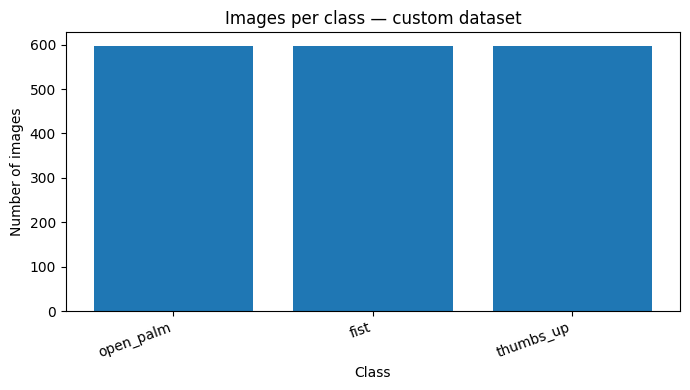

In [40]:
if len(image_paths) == 0:
    raise RuntimeError(
        f"No images found in {DATA_DIR}. "
        "Add images to the class folders or change DATASET_MODE."
    )

missing_classes = [name for name, count in counts.items() if count == 0]
if missing_classes:
    raise RuntimeError(
        "The following classes have no images: "
        + ", ".join(missing_classes)
        + f"\nExpected folders inside: {DATA_DIR}"
    )

plt.figure(figsize=(7, 4))
plt.bar(counts.keys(), counts.values())
plt.title(f"Images per class — {DATASET_MODE} dataset")
plt.xlabel("Class")
plt.ylabel("Number of images")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.savefig(OUTPUTS_DIR / f"{MODEL_TAG}_class_counts.png", dpi=150)
plt.show()

## 5. Visualize sample images

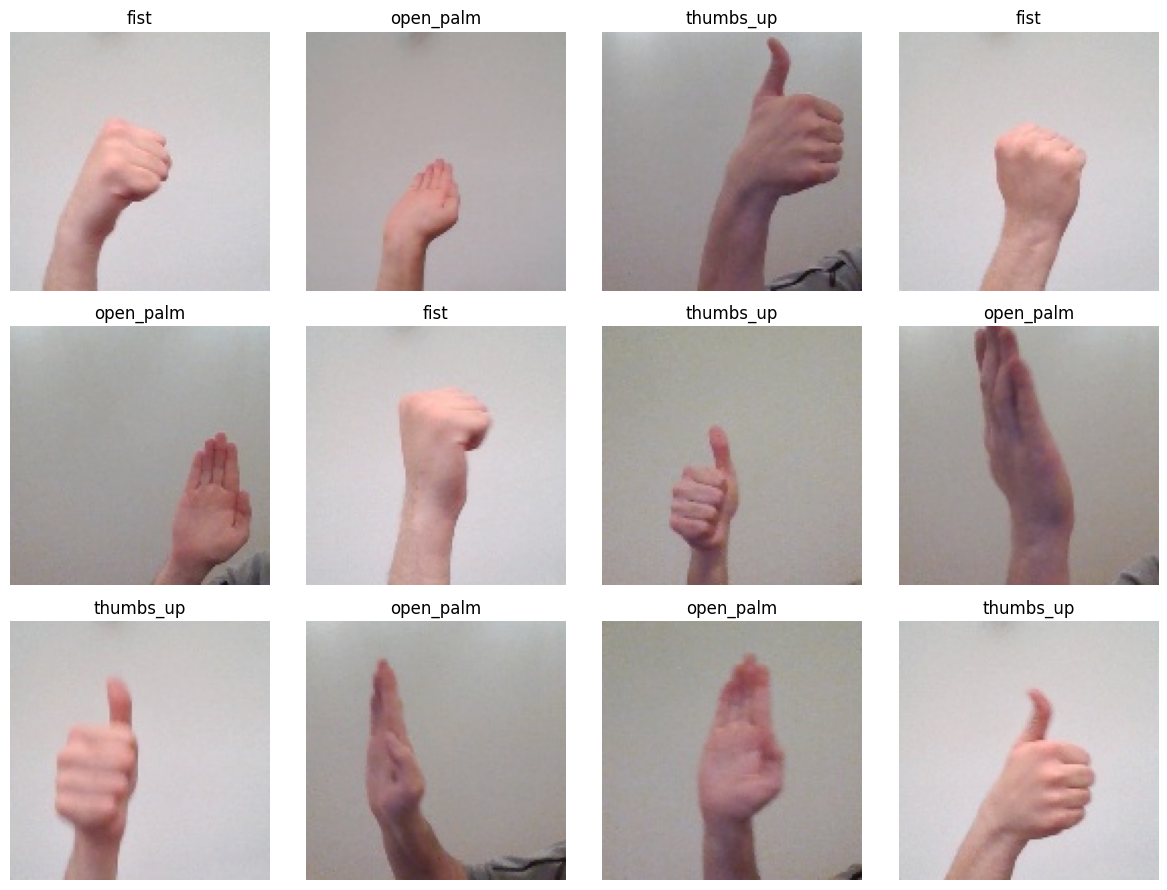

In [41]:
def show_random_examples(image_paths, labels, class_names, n=12):
    n = min(n, len(image_paths))
    idxs = random.sample(range(len(image_paths)), n)

    cols = 4
    rows = int(np.ceil(n / cols))
    plt.figure(figsize=(12, 3 * rows))

    for plot_i, idx in enumerate(idxs, start=1):
        image_path = image_paths[idx]
        label = labels[idx]

        image = keras.utils.load_img(image_path)

        plt.subplot(rows, cols, plot_i)
        plt.imshow(image)
        plt.title(class_names[label])
        plt.axis("off")

    plt.tight_layout()
    plt.savefig(OUTPUTS_DIR / f"{MODEL_TAG}_sample_images.png", dpi=150)
    plt.show()


show_random_examples(image_paths, labels, class_names, n=12)

## 6. Train/validation/test split

In [42]:
if len(class_names) < 2:
    raise RuntimeError("You need at least two classes for classification.")

min_count = min(counts.values()) if counts else 0
if min_count < 10:
    raise RuntimeError(
        "Each class should contain at least 10 images for a reliable stratified split. "
        "For a better project result, use around 150–300 images per class."
    )

train_val_paths, test_paths, train_val_labels, test_labels = train_test_split(
    image_paths,
    labels,
    test_size=0.15,
    random_state=SEED,
    stratify=labels,
)

train_paths, val_paths, train_labels, val_labels = train_test_split(
    train_val_paths,
    train_val_labels,
    test_size=0.1765,  # approximately 15% of full dataset
    random_state=SEED,
    stratify=train_val_labels,
)

print(f"Train:      {len(train_paths)}")
print(f"Validation: {len(val_paths)}")
print(f"Test:       {len(test_paths)}")

Train:      1255
Validation: 269
Test:       270


## 7. TensorFlow input pipeline

In [43]:
def load_and_preprocess_image(path, label):
    image_bytes = tf.io.read_file(path)
    image = tf.io.decode_image(image_bytes, channels=3, expand_animations=False)
    image.set_shape([None, None, 3])
    image = tf.image.resize(image, IMG_SIZE)
    image = tf.cast(image, tf.float32) / 255.0
    return image, label


def make_dataset(paths, labels, training: bool):
    ds = tf.data.Dataset.from_tensor_slices((paths, labels))

    if training:
        ds = ds.shuffle(
            buffer_size=len(paths),
            seed=SEED,
            reshuffle_each_iteration=True,
        )

    ds = ds.map(load_and_preprocess_image, num_parallel_calls=AUTOTUNE)
    ds = ds.batch(BATCH_SIZE)
    ds = ds.prefetch(AUTOTUNE)
    return ds


train_ds = make_dataset(train_paths, train_labels, training=True)
val_ds = make_dataset(val_paths, val_labels, training=False)
test_ds = make_dataset(test_paths, test_labels, training=False)

for images, batch_labels in train_ds.take(1):
    print("Image batch shape:", images.shape)
    print("Label batch shape:", batch_labels.shape)

Image batch shape: (32, 128, 128, 3)
Label batch shape: (32,)


## 8. Build the DCNN and ViT model

The model is a custom DCNN built from convolutional blocks. The convolutional layers learn local visual patterns such as edges, contours, fingers, and hand shapes. The final dense layers perform multiclass classification.

We also have another custom model which is a Vision Transformer. In this architecture, the input image is not processed mainly through convolutional feature maps, as in the DCNN. Instead, the image is divided into smaller patches, and these patches are treated as a sequence of visual tokens. The Transformer block then uses self-attention to learn relationships between different image regions. This is useful because the model can compare distant parts of the hand image, for example the relation between the palm, fingers, and thumb position.

In [44]:
num_classes = len(class_names)

data_augmentation = keras.Sequential(
    [
        layers.RandomFlip("horizontal"),
        layers.RandomRotation(0.08),
        layers.RandomZoom(0.10),
        layers.RandomContrast(0.10),
    ],
    name="data_augmentation",
)

# First architecture: Deep Convolutional Neural Networks
def build_dcnn(input_shape=(128, 128, 3), num_classes=3):
    inputs = keras.Input(shape=input_shape)

    x = data_augmentation(inputs)

    x = layers.Conv2D(32, 3, padding="same", use_bias=False)(x)
    x = layers.BatchNormalization()(x)
    x = layers.ReLU()(x)
    x = layers.MaxPooling2D()(x)

    x = layers.Conv2D(64, 3, padding="same", use_bias=False)(x)
    x = layers.BatchNormalization()(x)
    x = layers.ReLU()(x)
    x = layers.MaxPooling2D()(x)

    x = layers.Conv2D(128, 3, padding="same", use_bias=False)(x)
    x = layers.BatchNormalization()(x)
    x = layers.ReLU()(x)
    x = layers.MaxPooling2D()(x)

    x = layers.Conv2D(256, 3, padding="same", use_bias=False)(x)
    x = layers.BatchNormalization()(x)
    x = layers.ReLU()(x)

    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(0.40)(x)
    x = layers.Dense(128, activation="relu")(x)
    x = layers.Dropout(0.25)(x)

    outputs = layers.Dense(num_classes, activation="softmax")(x)

    model = keras.Model(inputs, outputs, name="hand_gesture_dcnn")
    return model

# Second architecture: Vision Transformer
def build_vit(input_shape=(128, 128, 3), num_classes=3):
    inputs = keras.Input(shape=input_shape)
    x = data_augmentation(inputs)

    patch_size = 16
    projection_dim = 64
    num_patches = (input_shape[0] // patch_size) * (input_shape[1] // patch_size)

    # Patch Extraction & Projection (χρησιμοποιώντας Conv2D)
    patches = layers.Conv2D(filters=projection_dim, kernel_size=patch_size, strides=patch_size)(x)
    patches = layers.Reshape(target_shape=(num_patches, projection_dim))(patches)

    # Positional Embeddings
    positions = tf.range(start=0, limit=num_patches, delta=1)
    pos_emb = layers.Embedding(input_dim=num_patches, output_dim=projection_dim)(positions)
    x = patches + pos_emb

    # Transformer Block (Attention + MLP)
    x1 = layers.LayerNormalization()(x)
    attention_output = layers.MultiHeadAttention(num_heads=4, key_dim=projection_dim)(x1, x1)
    x2 = layers.Add()([attention_output, x])

    x3 = layers.LayerNormalization()(x2)
    mlp_output = layers.Dense(projection_dim * 2, activation="gelu")(x3)
    mlp_output = layers.Dropout(0.3)(mlp_output)
    mlp_output = layers.Dense(projection_dim)(mlp_output)
    mlp_output = layers.Dropout(0.3)(mlp_output)
    x = layers.Add()([mlp_output, x2])

    # Classification Head
    representation = layers.GlobalAveragePooling1D()(x)
    representation = layers.Dropout(0.3)(representation)
    outputs = layers.Dense(num_classes, activation="softmax")(representation)

    return keras.Model(inputs, outputs, name="hand_gesture_vit")

if MODEL_TYPE == "dcnn":
    model = build_dcnn(input_shape=(*IMG_SIZE, 3), num_classes=num_classes)
elif MODEL_TYPE == "vit":
    model = build_vit(input_shape=(*IMG_SIZE, 3), num_classes=num_classes)
else:
    raise ValueError("MODEL_TYPE must be 'dcnn' or 'vit'.")

#model = build_dcnn(input_shape=(*IMG_SIZE, 3), num_classes=num_classes)

model.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)

model.summary()

Model: "hand_gesture_dcnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_4 (InputLayer)      │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ data_augmentation (Sequential)  │ (None, 128, 128, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 128, 128, 32)   │           864 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 128, 128, 32)   │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_4 (ReLU)                  │ (None, 128, 128, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 64, 64, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 64, 64, 64)     │        18,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 64, 64, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_5 (ReLU)                  │ (None, 64, 64, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_4 (MaxPooling2D)  │ (None, 32, 32, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 32, 32, 128)    │        73,728 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_6           │ (None, 32, 32, 128)    │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_6 (ReLU)                  │ (None, 32, 32, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_5 (MaxPooling2D)  │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_8 (Conv2D)               │ (None, 16, 16, 256)    │       294,912 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_7           │ (None, 16, 16, 256)    │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_7 (ReLU)                  │ (None, 16, 16, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 256)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_7 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_8 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 3)              │           387 │
└─────────────────────────────────┴────────────────────────┴─────────────

 Total params: 423,139 (1.61 MB)

 Trainable params: 422,179 (1.61 MB)

 Non-trainable params: 960 (3.75 KB)

## 9. Train the model

In [45]:
callbacks = [
    keras.callbacks.ModelCheckpoint(
        filepath=str(BEST_MODEL_PATH),
        monitor="val_accuracy",
        mode="max",
        save_best_only=True,
        verbose=1,
    ),
    keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=30,
        restore_best_weights=True,
        verbose=1,
    ),
    keras.callbacks.ReduceLROnPlateau(
        monitor="val_loss",
        factor=0.3,
        patience=3,
        min_lr=1e-6,
        verbose=1,
    ),
]

history = model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS,
    callbacks=callbacks,
)

Epoch 1/30
40/40 ━━━━━━━━━━━━━━━━━━━━ 0s 88ms/step - accuracy: 0.4867 - loss: 1.0484
Epoch 1: val_accuracy improved from None to 0.33086, saving model to /home/sfars/projects/dmci201/models/hand_gesture_dcnn_custom_best.keras

Epoch 1: finished saving model to /home/sfars/projects/dmci201/models/hand_gesture_dcnn_custom_best.keras
40/40 ━━━━━━━━━━━━━━━━━━━━ 7s 100ms/step - accuracy: 0.5418 - loss: 0.9512 - val_accuracy: 0.3309 - val_loss: 1.1843 - learning_rate: 0.0010
Epoch 2/30
39/40 ━━━━━━━━━━━━━━━━━━━━ 0s 58ms/step - accuracy: 0.6597 - loss: 0.7543
Epoch 2: val_accuracy did not improve from 0.33086
40/40 ━━━━━━━━━━━━━━━━━━━━ 2s 60ms/step - accuracy: 0.6829 - loss: 0.7227 - val_accuracy: 0.3309 - val_loss: 1.3030 - learning_rate: 0.0010
Epoch 3/30
39/40 ━━━━━━━━━━━━━━━━━━━━ 0s 56ms/step - accuracy: 0.7421 - loss: 0.6169
Epoch 3: val_accuracy improved from 0.33086 to 0.33457, saving model to /home/sfars/projects/dmci201/models/hand_gesture_dcnn_custom_best.keras

Epoch 3: finished sa

## 10. Training curves

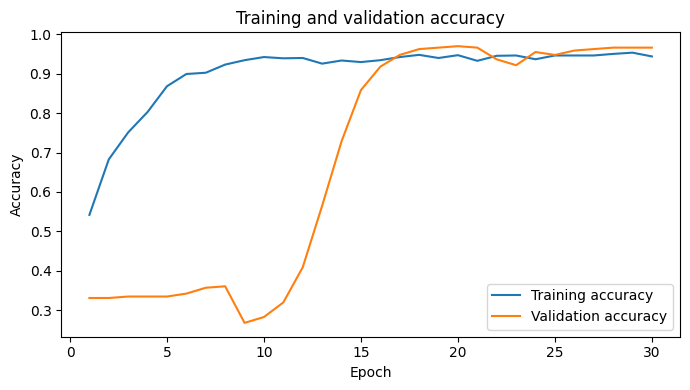

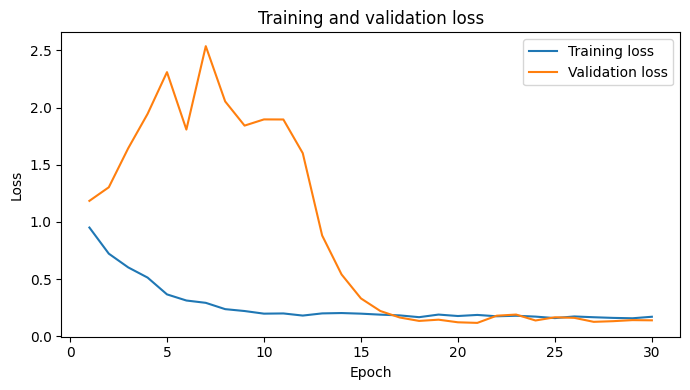

In [46]:
def plot_training_history(history):
    acc = history.history.get("accuracy", [])
    val_acc = history.history.get("val_accuracy", [])
    loss = history.history.get("loss", [])
    val_loss = history.history.get("val_loss", [])

    epochs_range = range(1, len(acc) + 1)

    plt.figure(figsize=(7, 4))
    plt.plot(epochs_range, acc, label="Training accuracy")
    plt.plot(epochs_range, val_acc, label="Validation accuracy")
    plt.title("Training and validation accuracy")
    plt.xlabel("Epoch")
    plt.ylabel("Accuracy")
    plt.legend()
    plt.tight_layout()
    plt.savefig(OUTPUTS_DIR / f"{MODEL_TAG}_accuracy_curve.png", dpi=150)
    plt.show()

    plt.figure(figsize=(7, 4))
    plt.plot(epochs_range, loss, label="Training loss")
    plt.plot(epochs_range, val_loss, label="Validation loss")
    plt.title("Training and validation loss")
    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.legend()
    plt.tight_layout()
    plt.savefig(OUTPUTS_DIR / f"{MODEL_TAG}_loss_curve.png", dpi=150)
    plt.show()


plot_training_history(history)

## 11. Test-set evaluation

In [47]:
if BEST_MODEL_PATH.exists():
    model = keras.models.load_model(BEST_MODEL_PATH)
    print("Loaded best model:", BEST_MODEL_PATH)

test_loss, test_acc = model.evaluate(test_ds, verbose=0)
print(f"Test loss:     {test_loss:.4f}")
print(f"Test accuracy: {test_acc:.4f}")

Loaded best model: /home/sfars/projects/dmci201/models/hand_gesture_dcnn_custom_best.keras
Test loss:     0.1411
Test accuracy: 0.9556


In [48]:
def collect_predictions(model, ds):
    y_true = []
    y_pred = []
    y_prob = []

    for batch_images, batch_labels in ds:
        probs = model.predict(batch_images, verbose=0)
        preds = np.argmax(probs, axis=1)

        y_true.extend(batch_labels.numpy().tolist())
        y_pred.extend(preds.tolist())
        y_prob.extend(probs.tolist())

    return np.array(y_true), np.array(y_pred), np.array(y_prob)


y_true, y_pred, y_prob = collect_predictions(model, test_ds)

print(classification_report(
    y_true,
    y_pred,
    target_names=class_names,
    digits=4,
))

              precision    recall  f1-score   support

   open_palm     1.0000    0.9778    0.9888        90
        fist     0.9158    0.9667    0.9405        90
   thumbs_up     0.9540    0.9222    0.9379        90

    accuracy                         0.9556       270
   macro avg     0.9566    0.9556    0.9557       270
weighted avg     0.9566    0.9556    0.9557       270



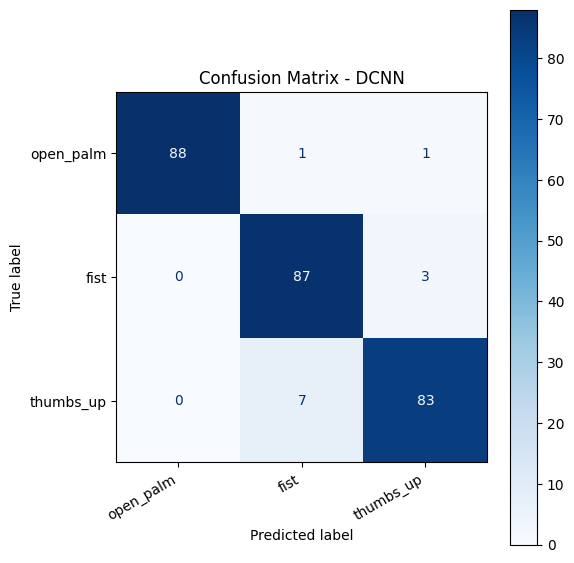

In [49]:
cm = confusion_matrix(y_true, y_pred)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names)
fig, ax = plt.subplots(figsize=(6, 6))
disp.plot(ax=ax, cmap="Blues", values_format="d")
plt.title(f"Confusion Matrix - {MODEL_TYPE.upper()}")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.savefig(OUTPUTS_DIR / f"{MODEL_TAG}_confusion_matrix.png", dpi=150)
plt.show()

## 12. Inspect incorrect predictions

Incorrect predictions: 12


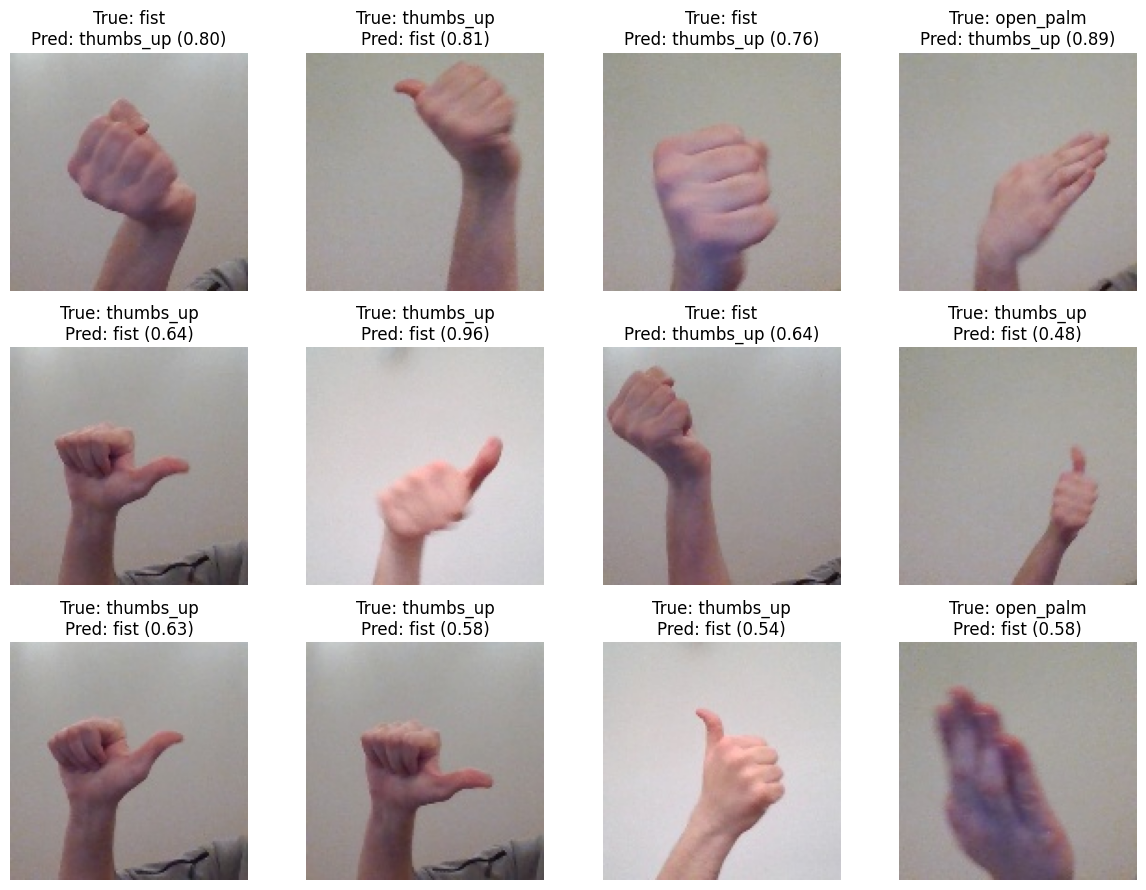

In [50]:
def predict_single_image(model, image_path):
    img_bytes = tf.io.read_file(str(image_path))
    img = tf.io.decode_image(img_bytes, channels=3, expand_animations=False)
    img = tf.image.resize(img, IMG_SIZE)
    img = tf.cast(img, tf.float32) / 255.0
    probs = model.predict(tf.expand_dims(img, axis=0), verbose=0)[0]
    pred_id = int(np.argmax(probs))
    return pred_id, float(probs[pred_id]), probs


incorrect_indices = np.where(y_true != y_pred)[0]
print("Incorrect predictions:", len(incorrect_indices))

n_show = min(12, len(incorrect_indices))
if n_show > 0:
    chosen = random.sample(list(incorrect_indices), n_show)

    cols = 4
    rows = int(np.ceil(n_show / cols))
    plt.figure(figsize=(12, 3 * rows))

    for plot_i, idx in enumerate(chosen, start=1):
        path = test_paths[idx]
        true_label = class_names[y_true[idx]]
        pred_label = class_names[y_pred[idx]]
        conf = np.max(y_prob[idx])

        image = keras.utils.load_img(path)

        plt.subplot(rows, cols, plot_i)
        plt.imshow(image)
        plt.title(f"True: {true_label}\nPred: {pred_label} ({conf:.2f})")
        plt.axis("off")

    plt.tight_layout()
    plt.savefig(OUTPUTS_DIR / f"{MODEL_TAG}_incorrect_predictions.png", dpi=150)
    plt.show()
else:
    print("No incorrect predictions found on the test set.")

## 13. Save final model and class names

In [51]:
model.save(FINAL_MODEL_PATH)

with open(CLASS_NAMES_PATH, "w", encoding="utf-8") as f:
    json.dump(class_names, f, indent=2)

print("Saved final model to:", FINAL_MODEL_PATH)
print("Saved class names to:", CLASS_NAMES_PATH)

Saved final model to: /home/sfars/projects/dmci201/models/hand_gesture_dcnn_custom_final.keras
Saved class names to: /home/sfars/projects/dmci201/models/hand_gesture_dcnn_custom_class_names.json


## 14. Predict one image file

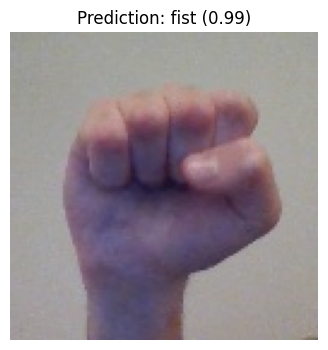

open_palm   : 0.0010
fist        : 0.9939
thumbs_up   : 0.0051


In [52]:
def show_prediction_for_image(image_path):
    image_path = Path(image_path)
    pred_id, confidence, probs = predict_single_image(model, image_path)

    image = keras.utils.load_img(image_path)

    plt.figure(figsize=(4, 4))
    plt.imshow(image)
    plt.axis("off")
    plt.title(f"Prediction: {class_names[pred_id]} ({confidence:.2f})")
    plt.show()

    for class_name, prob in zip(class_names, probs):
        print(f"{class_name:12s}: {prob:.4f}")


# Example:
show_prediction_for_image(test_paths[0])